In [1]:
import numpy as np
import torch
from torch import Tensor, nn
from torch.optim import Adam, Optimizer
from torch.utils.data import DataLoader
from torch.utils.data.dataset import IterableDataset
import time



from dqn_agent import DQNAgent
#from ddqn_agent import DDQNAgent
#from ddqn_agent import DDQNAgent
import gym
import random
import torch
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
%matplotlib inline

# frozen-lake-ex4.py
import gym
#env = gym.make("FrozenLake-v0", is_slippery=False)
#env = gym.make("CartPole-v1")

from environment import MapWalkingEnv

#env = MapWalkingEnv(10,10)


In [8]:
state = env.reset()
state_size=env.observation_space.n
state_arr=np.zeros(state_size)
state_arr[state] = 1
state= np.reshape(state_arr, [1, state_size])

In [19]:
if isinstance(env.observation_space, gym.spaces.Discrete):
    state = env.reset()
    state_size=env.observation_space.n
    state_arr=np.zeros(state_size)
    state_arr[state] = 1
    state = np.reshape(state_arr, [1, state_size])
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 

In [20]:
state_dim

4

In [11]:
state = env.reset()
state_size=env.observation_space.n
state_arr=np.zeros(state_size)
state_arr[state] = 1
state= np.reshape(state_arr, [1, state_size])

AttributeError: 'Box' object has no attribute 'n'

In [9]:
state

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [10]:
#Definition of states and actions

# S = ['A','B','C','D','E','F']
# A = ['A','B','C','D','E','F']

In [11]:
# # Initialize R matrix with np.nan in all cells
# R =  np.array([[np.nan for a in A] for s in S])

# # Populate R matrix with possible actions + rewards until it matches the R matrix given in the tutorial notes.
# R[0, 4] = 0 # door from room A to E, reward=0
# R[1, 3] = 0 # door from B to D, reward=0
# R[1, 5] = 100 # door from B to D, reward=100

# # Slightly faster: define these as a list.
# possible_actions = [(0,4), (1,3), (1,5), (2,3), (3, 1), (3,2), (3,4), (4,0), (4,3), (4,5), (5,1), (5,4), (5,5)]

# for s,a in possible_actions:
#     if a == 5:
#         R[s,a] = 100
#     else:
#         R[s,a] = 0
        
# print('R matrix: \n\n{}'.format(R))

R matrix: 

[[ nan  nan  nan  nan   0.  nan]
 [ nan  nan  nan   0.  nan 100.]
 [ nan  nan  nan   0.  nan  nan]
 [ nan   0.   0.  nan   0.  nan]
 [  0.  nan  nan   0.  nan 100.]
 [ nan   0.  nan  nan   0. 100.]]


In [9]:
ss = env.reset()
states_total = 16
data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
def encode(data, states_total):
    targets = np.array(data).reshape(-1)
    return np.eye(states_total)[targets]
m = encode(data,states_total)
s = m[ss]
print(s)

[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [10]:
MAX_ITERATIONS = 10
 
env = gym.make("FrozenLake-v0")
env.reset()
env.render()
for i in range(MAX_ITERATIONS):
    random_action = env.action_space.sample()
    new_state, reward, done, info = env.step(
       random_action)
    print(new_state)
    env.render()
    
    if done:
        break


SFFF
FHFH
FFFH
HFFG
1
  (Up)
SFFF
FHFH
FFFH
HFFG
2
  (Down)
SFFF
FHFH
FFFH
HFFG
2
  (Up)
SFFF
FHFH
FFFH
HFFG
6
  (Left)
SFFF
FHFH
FFFH
HFFG
7
  (Right)
SFFF
FHFH
FFFH
HFFG


In [8]:
env.reset()

0

In [5]:
env.reset()

array([ 1.18350981e-04,  1.40453386e+00,  1.19682625e-02, -2.83838421e-01,
       -1.30303975e-04, -2.71100202e-03,  0.00000000e+00,  0.00000000e+00],
      dtype=float32)

## DQN class

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DQNetwork(nn.Module):
    """Simple MLP network."""
    
    # Network initialisation
    def __init__(self, obs_size: int, hidden_size: int, n_actions: int, lr):
        """
        Args:
            obs_size: observation/state size of the environment
            n_actions: number of discrete actions available in the environment
            hidden_size: size of hidden layers
        """
        super().__init__()
        self.fc1 = nn.Linear(obs_size, hidden_size)   
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.out = nn.Linear(hidden_size, n_actions)
        
        self.optimizer = optim.Adam(self.parameters(),lr=lr)
        self.loss = nn.MSELoss()
        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

        
    # Forward propagation 
    def forward(self, state):
        x = state.flatten(start_dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        return x

In [6]:
qnetwork_local = DQNetwork(state_size=16, hidden_size=4, action_size=4, seed=0, lr=0)

In [3]:
from dqn_model import DeepQNetwork
qnetwork_local = DeepQNetwork(state_size=16, fc1_dim=4, fc2_dim=4, action_size=4, seed=0, lr=0)

In [13]:
print("Action space: ", env.action_space)

Action space:  Discrete(4)


In [29]:
torch.flatten(state,start_dim=1)

TypeError: flatten(): argument 'input' (position 1) must be Tensor, not int

In [10]:
torch.flatten(torch.from_numpy(np.array(state)).float().unsqueeze(0),start_dim=0)

tensor([0.])

In [4]:
env = gym.make('LunarLander-v2')
env.seed(0)
print('State shape: ', env.observation_space.shape)
print('Number of actions: ', env.action_space.n)

print(env.reset())

State shape:  (8,)
Number of actions:  4
[-5.9156417e-04  1.4134574e+00 -5.9935719e-02  1.1277095e-01
  6.9228926e-04  1.3576316e-02  0.0000000e+00  0.0000000e+00]


In [6]:
env.reset()

array([ 0.0075161 ,  1.4044806 ,  0.7612664 , -0.2862266 , -0.0087023 ,
       -0.17243806,  0.        ,  0.        ], dtype=float32)

In [58]:
agent = DQNAgent(state_size=16, hidden_size=64, action_size=4, seed=0, lr=0)

# watch an untrained agent
state = env.reset()

states_total = 16
data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
def encode(data, states_total):
    targets = np.array(data).reshape(-1)
    return np.eye(states_total)[targets]

for j in range(200):
    m = encode(data,states_total)
    s = m[state]
    action = agent.act(s)
    env.render()
    state, reward, done, _ = env.step(action)
    states_total = 16
    
    
    if done:
        break 
        
env.close()

TypeError: __init__() got an unexpected keyword argument 'hidden_size'

In [4]:
agent = DQNAgent(state_size=16, fc1_dim=64, fc2_dim=64, action_size=4, seed=0, lr=0.001)

In [44]:
batch = np.random.choice(20, 16, replace=False)
print(batch)
print(np.arange(16, dtype=np.int32))

[ 3 10 11  4  9 17 13  7  6  8 18  1 14 19  5  0]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]


In [ ]:
env.reset()
state_arr=np.zeros(state_size)
state_arr[state] = 1
state= np.reshape(state_arr, [1, state_size])

In [38]:
env.reset()

0

In [44]:
env.observation_space.n

16

In [42]:
def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_size])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

In [46]:
state=env.reset()

In [3]:
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)

def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 

action_dim=env.action_space.n

# CartPole    
# agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

#FrozenLake
agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
                 action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)

#MapWalking
#agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
#                 action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)


def DQN(num_episodes=4000, mem_count=1000, epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.995):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_t (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    scores_averaged = []
    epsilon = epsilon_start                    # initialize epsilon
    
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#     elif isinstance(env.observation_space, gym.spaces.Box):
#         state_shape = env.observation_space.shape
#         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
#     action_dim=env.action_space.n
    
#     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

    
    for i_episode in range(1, num_episodes+1):
        state = env.reset()
        
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        state = encode_state(env, gym, state)
        #print(state)
        score = 0
        for t in range(mem_count):
            action = agent.select_action(state, epsilon)
            next_state, reward, done, _ = env.step(action)
            #m = encode(data,states_total)
            #next_state = m[next_state]
            next_state = encode_state(env, gym, next_state)
            
            
            agent.step(state, action, reward, next_state, done)
            state = next_state
            #print(next_state,state)
            score += reward
            if done:
                break 
                
        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)), end="")
        if i_episode % 100 == 0:
            scores_averaged.append(np.mean(scores_window))
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
        if np.mean(scores_window)>=200.0:
            print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
            torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
            break
    return scores, scores_averaged

scores, scores_averaged = DQN()

# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(scores_averaged))*100, scores_averaged)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

NameError: name 'env' is not defined

In [23]:
env.s
state_a = np.array([env.s], copy=False)
print(state_a)
state_v = torch.tensor(state_a).to('cpu')
print(state_v)

[15]
tensor([15], dtype=torch.int32)


In [102]:
self.action_size = action_size
self.memory = deque(maxlen=int(1e5))  
self.batch_size = batch_size
self.experience = namedtuple("Experience", field_names=["state", "action", "reward", "next_state", "done"])
self.seed = random.seed(seed)

def add(self, state, action, reward, next_state, done):
    """Add a new experience to memory."""
    e = self.experience(state, action, reward, next_state, done)
    self.memory.append(e)

0

In [21]:
agent.qnetwork_local.fc1.weight.dtype

torch.float32

In [4]:
x = torch.tensor([[1, 2, 3, 4]])
torch.unsqueeze(x,2).dim()

3

In [6]:
x.shape

torch.Size([1, 4])

In [3]:
torch.from_numpy(np.array(state)).float().unsqueeze(0).to('cpu')

NameError: name 'state' is not defined

In [ ]:
.detach().max(1)[0].unsqueeze(1)

## Double DQN

In [16]:
def optimize_model(double = False):
    
    
        # Get max predicted Q values (for next states) from target model
        Q_targets_next = self.qnetwork_target(next_states).detach().max(1)[0].unsqueeze(1)
        # Compute Q targets for current states 
        Q_targets = rewards + (gamma * Q_targets_next * (1 - dones))

        # Get expected Q values from local model
        Q_expected = self.qnetwork_local(states).gather(1, actions)
		
		if ddqn:
			selected_actions = Q_target(non_final_next_states).max(1)[1].unsqueeze(1).detach()
			next_Q_values[non_final_mask] = self.qnetwork_target(non_final_next_states).gather(1, selected_actions).view(-1,).detach()
		else:
			next_Q_values[non_final_mask] = self.qnetwork_target(non_final_next_states).max(1)[0].detach()
		
        # Compute loss
        loss = F.mse_loss(Q_expected, Q_targets)
        
		# Minimize the loss
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # ------------------- update target network ------------------- #
        self.soft_update(self.qnetwork_local, self.qnetwork_target, TAU)     

In [17]:
env

<TimeLimit<FrozenLakeEnv<FrozenLake-v0>>>

In [4]:
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=0.001, gamma=0.995)
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)

def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

if isinstance(env.observation_space, gym.spaces.Discrete):
    state_dim=env.observation_space.n
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 

action_dim=env.action_space.n

# CartPole    
# agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

#FrozenLake
agent = DDQNAgent(state_size=state_dim, fc1_dim=4, fc2_dim=50, 
                 action_size=action_dim, seed=0, lr=0.001, gamma=0.995)


def DDQN(num_episodes=4000, mem_count=1000, epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.995):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_t (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    scores_averaged = []
    epsilon = epsilon_start                    # initialize epsilon
    
    for i_episode in range(1, num_episodes+1):
        state = env.reset()
        
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        state = encode_state(env, gym, state)
        #print(state)
        score = 0
        for t in range(mem_count):
            action = agent.select_action(state, epsilon)
            next_state, reward, done, _ = env.step(action)
            #m = encode(data,states_total)
            #next_state = m[next_state]
            next_state = encode_state(env, gym, next_state)
            
            
            agent.step(state, action, reward, next_state, done)
            state = next_state
            #print(next_state,state)
            score += reward
            if done:
                break 
                
        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)), end="")
        if i_episode % 100 == 0:
            scores_averaged.append(np.mean(scores_window))
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
        if np.mean(scores_window)>=200.0:
            print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
            torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
            break
    return scores, scores_averaged

scores, scores_averaged = DDQN()

# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(scores_averaged))*100, scores_averaged)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

NameError: name 'env' is not defined

# 4 Last experiment (Dueling Double Deep Q Network With Prioritized Replay)

### Dueling Double Deep Q Network With Double Attention

In [ ]:
class DuelingDQN(nn.Module):
    """
    Class for implementing the duelling DQN architcture
    Used here for the purpose of loading the class
    """
    def __init__(self, num_inputs, num_outputs):
        super(DuelingDQN, self).__init__()
        
        
        self.feature = nn.Sequential(
            nn.Linear(num_inputs, 128),
            nn.ReLU()
        )
        
        self.advantage = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_outputs)
        )
        
        self.value = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
        
    def forward(self, x):
        x = self.feature(x)
        advantage = self.advantage(x)
        value     = self.value(x)
        return value + advantage  - advantage.mean()

In [ ]:
Our Environment

In [5]:
#These are the key actions you can apply at states
action_dict = {
    0: 'up',
    1: 'down',
    2: 'right',
    3: 'left',
    4: 'pickup',
    5: 'dropoff',
    6: 'open'
}

#Colours for environment
color2num = dict(
    gray=30,
    red=31,
    green=32,
    yellow=33,
    blue=34,
    magenta=35,
    cyan=36,
    white=37,
    crimson=38,
)

#Function to surround string with certain colour codes
def colorise(string, color, bold=False, highlight=False):
    attr = []
    num = color2num[color]
    if highlight:
        num += 10
    attr.append(str(num))
    if bold:
        attr.append("1")
    attrs = ";".join(attr)
    return f"\x1b[{attrs}m{string}\x1b[0m"

# A function that counts the number of true values when the cumulative sum of n probabilities
#In an array is greater than a randomly generated number used in the step function




# Own Environment

In [7]:
from environment import MapWalkingEnv
env = MapWalkingEnv(10,10)

In [8]:
env.reset()

NameError: name 'categorical_sample' is not defined

In [38]:
agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
                action_size=action_dim, seed=0, lr=0.005, gamma=0.99)


Episode 10	Average Rewards: -273.00	Sum Rewards: -220.00
Episode 20	Average Rewards: -243.15	Sum Rewards: -251.00
Episode 30	Average Rewards: -226.47	Sum Rewards: -257.00
Episode 40	Average Rewards: -241.60	Sum Rewards: -119.00
Episode 50	Average Rewards: -244.06	Sum Rewards: -303.00
Episode 60	Average Rewards: -250.33	Sum Rewards: -292.00
Episode 70	Average Rewards: -256.63	Sum Rewards: -315.00
Episode 80	Average Rewards: -260.68	Sum Rewards: -317.00
Episode 90	Average Rewards: -261.22	Sum Rewards: -311.00
Episode 100	Average Rewards: -263.16	Sum Rewards: -306.00
132.90760207176208


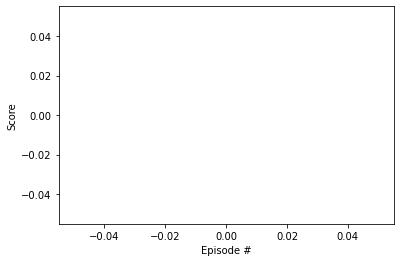

In [4]:
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)



def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    elif env.__class__.__name__ == 'MapWalkingEnv':
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    return state


env = MapWalkingEnv(10,10)
    

if isinstance(env.observation_space, gym.spaces.Discrete):
    state_dim = env.observation_space.n
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
else:
    state_dim = env.observation_space.n
    
action_dim=env.action_space.n

# CartPole    
# agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

#FrozenLake
# agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
#                  action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)

#MapWalking
# agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
#                 action_size=action_dim, seed=0, lr=0.005, gamma=0.9)

#MapWalking
agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
                action_size=action_dim, seed=0, lr=0.001, gamma=0.9)

def DQN(num_episodes=100, max_timesteps=200, epsilon_start=0.5, epsilon_end=0.01, epsilon_decay=0.999, qtarget_update=5):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_timesteps (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    scores_averaged = []
    epsilon = epsilon_start                    # initialize epsilon
    
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#     elif isinstance(env.observation_space, gym.spaces.Box):
#         state_shape = env.observation_space.shape
#         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
#     action_dim=env.action_space.n
    
#     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)
    

    env = MapWalkingEnv(10,10)
    rewards = np.zeros([num_episodes,max_timesteps])
    
    for i_episode in range(1, num_episodes+1):
        state = env.reset()
        
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        #state = encode_state(env, gym, state)
        
        #print(state)
        score = 0
        for t in range(max_timesteps):
            valid_actions = env.valid_actions()
            #print('Before',env.s,valid_actions)
            action = agent.select_action(state, valid_actions, epsilon)
            
#             if env.P[env.s][action] == []:
#                 while env.P[env.s][action] == []:
#                     action = agent.select_action(state, epsilon)        
            #print('After',env.s, action, valid_actions)        
            next_state, reward, done, _ = env.step(action)
            #next_state = encode_state(env, gym, next_state)      
            
            agent.step(state, action, reward, next_state, done)
            rewards[i_episode-1][t] = reward
            state = next_state
            #print(next_state,state)
            score += reward
            if done:
                break 
        # Update the target network, copying all weights and biases in DQN
        if i_episode % qtarget_update == 0:
            agent.update_target_network()    

        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        if i_episode % 10 == 0:
            print('\rEpisode {}\tAverage Rewards: {:.2f}'.format(i_episode, np.mean(scores)), end="")
            print('\tSum Rewards: {0:.2f}'.format(score))
#         if i_episode % 100 == 0:
#             scores_averaged.append(np.mean(scores_window))
#             print('\n\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
#         if np.mean(scores_window)>=200.0:
#             print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
#             torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
#             break
    return scores, scores_averaged, rewards

start = time.time()
rewards_total, rewards_averaged, rewards = DQN()
end = time.time()
print(end - start)
# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(rewards_averaged))*100, rewards_averaged)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

In [5]:
env.P[104]

{0: [(1.0, 24, 0, False)],
 1: [(1.0, 184, 0, False)],
 2: [(1.0, 112, 0, False)],
 3: [(1.0, 96, 0, False)],
 4: [(1.0, 104, -20, False)],
 5: [(1.0, 104, -20, False)],
 6: [(1.0, 104, -20, False)]}

In [36]:
embedding = torch.nn.Embedding(500, 4)

print(embedding.weight)

print(embedding(torch.tensor([1])))

Parameter containing:
tensor([[ 4.8315e-01,  1.1608e+00, -6.0057e-01, -5.2111e-01],
        [ 2.0086e+00,  1.0887e+00,  6.2193e-01, -1.1411e+00],
        [ 7.7739e-01, -2.5331e-01,  5.5779e-01,  7.2611e-02],
        ...,
        [ 2.7153e-01,  1.0470e+00, -8.0712e-01, -3.5622e-01],
        [ 1.2390e+00, -1.4534e+00,  1.0629e-03,  9.6432e-01],
        [ 3.9099e-01, -2.2425e+00,  1.9312e+00, -1.2399e+00]],
       requires_grad=True)
tensor([[ 2.0086,  1.0887,  0.6219, -1.1411]], grad_fn=<EmbeddingBackward>)


In [4]:
# encode_state(env, gym, state):
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#         state_arr=np.zeros(state_dim)
#         state_arr[state] = 1
#         state = np.reshape(state_arr, [1, state_dim])
#     #elif isinstance(env.observation_space, gym.spaces.Box):
#     #    state_shape = env.observation_space.shape
#     #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
#     return state

env = MapWalkingEnv(10,10)

env.reset()

a = encode_state(env,gym,526)

In [17]:
1 * pow(0.999,5000)

0.006721111959865588

In [19]:
a = torch.tensor([[0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [22]:
torch.sum(a).item() 

2.0

In [ ]:
import numpy as np
from discrete_space import Discrete

class MapWalkingEnv:

    def __init__(self, N, M):
        # Numpy array that holds the information about the environment
        self.territory = np.zeros((N, M), dtype = np.int8)
        self.height = N
        self.width = M
        self.size = N * M 
        self.average_size = round((N+M)/2,0)
        self.hostage = 1 # 1 hostage zones
        self.exit = 2 # 1 safe zone and 1 unsafe
        
        # Number of random objects
        self.number_keys = 1
        self.number_hostages = 1
        self.number_mines = 1
        self.exit_steps = None 

        # Define Walls (Static coordinates)
        wall_states = [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)]
        
        for i,j in wall_states:
            self.territory[i,j] = 1
        
        # Pick coordinates for the mine
        self.mine_coord = mine_coord = (0,9) # Static coordinates
        self.territory[mine_coord[0], mine_coord[1]] = 2

        # Pick 2 random coordinates to the safe zone and unsafe zone respectively
        #self.exit_coord = exit_coord = self.get_exit_cells(self.exit) # Dynamic coordinates
        self.exit_coord = exit_coord = ((0,8),(9,9))  # Static coordinates
        self.territory[exit_coord[0][0], exit_coord[0][1]] = 5 # Safe
        self.territory[exit_coord[1][0], exit_coord[1][1]] = 6 # Unsafe
        
        # Pick 1 random coordinate for the key
        #self.key_coord = key_coord = self.get_empty_cells(self.number_keys) # Dynamic coordinates
        self.key_coord = key_coord = (5,7) # Static coordinates
        self.territory[key_coord[0],key_coord[1]] = 3
         
        # Pick 1 random coordinate for the hostage zone
        #self.hostage_coord = hostage_coord = self.get_empty_cells(self.number_hostages) # Dynamic coordinates
        self.hostage_coord = hostage_coord = (9,8) # Static coordinates
        self.territory[hostage_coord[0],hostage_coord[1]] = 4
        
        # initial position of the agent will be decided by resetting the environment.
        self.position_agent = None
        self.start_agent = None

        # run time
        self.time_elapsed = 0
        self.time_limit = 2*self.size #* 8

        # display help
        self.dict_map_display={ 0:'.', #0 : empty cell
                                1:'X', #1 : walls obstacle that are non-traversable
                                2:'M', #2 : mine field location
                                3:'K', #3 : key location
                                4:'H', #3 : hostage zone    
                                5:'S', #4 : safe zone
                                6:'U', #6 : unsafe zone
                                7:'A' #7 : agent location
                              }
       

        num_states = self.size * 8
        num_rows = N
        num_columns = M
        max_row = num_rows - 1
        max_col = num_columns - 1
        self.initial_state_distrib = np.zeros(num_states)
        num_actions = 7
        
        # Set available actions
        self.actions = [0,1,2,3,4,5,6]
        #self.actions = ['up','down','left','right','pickup','dropoff','open']
        
        self.P = {
            state: {action: [] for action in range(num_actions)}
            for state in range(num_states)
        }
        self.states_array = {
            state   : {}
            for state in range(num_states)
        }
        self.observations_array = {
            state   : {}
            for state in range(num_states)
        }
        
        # Create matrix of possible transitions, essentially like R matrix
        for row in range(num_rows): #7
            for col in range(num_columns): #7
                for key_idx in range(2): # +1 for key being with agent
                    for host_idx in range(2): # +1 for host being with agent
                        for exit_idx in range(2): # for tracking if door was opened or not
                            state = self.encode(row, col, key_idx, host_idx, exit_idx)

                            if  (self.territory[row, col] != 1) \
                                and self.territory[row, col] != 2 \
                                and (key_idx < 1 and host_idx < 1 and exit_idx < 1):
                                self.initial_state_distrib[state] += 1
                                self.states_array[state] = (row, col)
                            if  self.territory[row, col] != 1: 
                                self.observations_array[state] = (row, col)
                            
                            valid_actions = self.valid_actions(row, col)
                            
                            for action in valid_actions:
                                # defaults
                                new_row, new_col, new_key_idx, new_host_idx, new_exit_idx=row, col, key_idx, host_idx, exit_idx
                                reward = (
                                    0 #-0.1
                                )  # Default reward when there is no pickup/dropoff/open and agent moves to an open cell
                                
                                done = False
                                agent_loc = (row, col)
                                

                                if action == 0: #'up' 
                                    new_row = max(row - 1, 0)
                                elif action == 1: #'down' 
                                    new_row = min(row + 1, max_row)
                                elif action == 2: #'right' 
                                    new_col = min(col + 1, max_col)
                                elif action == 3: #'left':
                                    new_col = max(col - 1, 0)
                                elif action == 4: #'pickup' 
                                    if new_host_idx == 0 and new_key_idx == 1 and new_exit_idx == 1 and \
                                    (agent_loc == (hostage_coord[0],hostage_coord[1])):
                                        new_host_idx = 1
                                        reward = 200
                                    elif new_key_idx == 0 and (agent_loc == (key_coord[0],key_coord[1])):
                                        new_key_idx = 1
                                        reward = 200
                                    elif self.territory[new_row, new_col] != 2: # key not at location or agent did not open a door yet
                                        reward = -2
                                elif action == 5: #'dropoff' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1]) and \
                                        new_key_idx == 1 and new_host_idx == 1):
                                        done = True
                                        reward = 1000
                                    elif agent_loc == (exit_coord[1][0],exit_coord[1][1]) : #(agent_loc == (exit_coord[0][0],exit_coord[0][1]) and (new_key_idx == 0)) or \
                                        done = True
                                        reward = -10
                                    elif self.territory[new_row, new_col] != 2:  # dropoff at wrong location
                                        reward = -2
                                elif action == 6: #'open' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1])) and (new_key_idx == 1 and new_exit_idx == 0):
                                        new_exit_idx = 1
                                        reward = 200
                                    elif self.territory[new_row, new_col] != 2:  # open at wrong location
                                        reward = -2

                                if (new_host_idx == 1 and new_key_idx == 1) or \
                                    new_exit_idx == 1:
                                    new_exit_idx=1
                                else:
                                    new_exit_idx=0
                                    
                                # If the agent bumps into a wall, it doesn't move
                                if self.territory[new_row, new_col] == 1:
                                    new_row = row
                                    new_col = col
                                    reward = -1
                                
                                # If the agent bumps into a mine it reaches a terminal state:
                                if self.territory[new_row, new_col] == 2:
                                    new_row = row
                                    new_col = col
                                    done = True
                                    reward = -100 

                                if self.territory[row, col] != 1 and self.territory[row, col] != 2:
                                    new_state = self.encode(
                                        new_row, new_col, new_key_idx, new_host_idx, new_exit_idx
                                    )
                                    
                                    self.P[state][action].append((1.0, new_state, reward, done))
                       
        self.initial_state_distrib /= self.initial_state_distrib.sum()
        self.action_space = Discrete(num_actions) #int(num_actions)
        self.observation_space = Discrete(num_states) # Encoded states shape
        self.observation_space_decoded = len(list(self.decode(Discrete(0)))) # Decoded states shape
        
    def get_empty_cells(self, n_cells):
        empty_cells_coord = np.where( self.territory == 0 )
        selected_indices = np.random.choice( np.arange(len(empty_cells_coord[0])), n_cells )
        selected_coordinates = empty_cells_coord[0][selected_indices], empty_cells_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
        
    def get_exit_cells(self, n_cells):
        y=np.arange(self.territory.shape[0] * self.territory.shape[1]).reshape(self.territory.shape[0], self.territory.shape[1])        
        border_coord_indices = list(np.unique(np.array(sorted(np.concatenate([y[0,:],y[-1,:],y[:,0], y[:,-1]]))).reshape(1,-1)))
        border_coord=np.zeros((2,len(border_coord_indices)),dtype = np.int8)
        border_coord[0] = [int(i) for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        border_coord[1] = [j for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        #print(border_coord_indices)
        #print(border_coord)
        selected_indices = np.random.choice( np.arange(len(border_coord[0])), n_cells )
        selected_coordinates = border_coord[0][selected_indices], border_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
    
    
    # a key function for the q learning update rule
    def step(self, action):
        transitions = self.P[self.s][action]
        i = self.categorical_sample([t[0] for t in transitions], np.random)
        p, state, reward, done = transitions[i]
        self.s = state
        self.lastaction = action
        
        if done == False:
            self.position_agent = (self.observations_array[self.s][0],self.observations_array[self.s][1])

        # Update time elapsed
        self.time_elapsed+=1
        
        _, _, _, _, self.exit_steps = self.decode(self.s)

        if self.time_elapsed == self.time_limit:
            done = True
        
        return (int(state), reward, done, {"prob": p})
   

    def agent_on_map(self):
        #prints out current location of agent on the grid
        grid = np.zeros((self.N, self.M))
        grid[ self.current_location[0], self.current_location[1]] = 1
        return grid
    
    
    def encode(self, agent_row, agent_col, key_idx, host_idx, exit_idx):
        i = agent_row
        i *= 10
        i += agent_col
        i *= 2
        i += key_idx
        i *= 2
        i += host_idx
        i *= 2
        i += exit_idx
        return i

    def decode(self, i):
        out = []
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 10)
        i = i // 10
        out.append(i)
        assert 0 <= i < 10
        return reversed(out)
    
    def categorical_sample(self, prob_n, np_random):
        prob_n = np.asarray(prob_n)
        csprob_n = np.cumsum(prob_n)
        return (csprob_n > np_random.random()).argmax()
    
    def display(self, mode='human'):
 
        envir_with_agent = self.territory.copy()
        envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        
        agent_row, agent_col, key_idx, host_idx, exit_idx = self.decode(self.s)

        full_repr = ""

        for r in range(self.height):
            
            line = ""
            
            for c in range(self.width):
                
                string_repr = self.dict_map_display[ envir_with_agent[r,c] ]
                line += "{0:2}".format(string_repr)

            full_repr += line + "\n"
        
        if key_idx == 1 and exit_idx == 0: # Agent found the key but did not open the door yet
            full_repr = full_repr.replace('A',colorize('A', "yellow", highlight=True))
        elif exit_idx == 1 and host_idx == 0: # Agent opened the door but did not find hostage
            full_repr = full_repr.replace('A',colorize('A', "blue", highlight=True))
        elif host_idx == 1: # Agent found the hostage
            full_repr = full_repr.replace('A',colorize('A', "green", highlight=True))

        print('Key (Yellow):',key_idx,'/ Door (Blue):',exit_idx,'/ Hostage (Green):',host_idx,'- Agent start',self.start_agent)
        print(full_repr)

        
    def calculate_observations(self):
        
        relative_coordinates = self.position_exit - self.position_agent
                
        surroundings = self.territory[ self.position_agent[0] -1: self.position_agent[0] +2,
                                     self.position_agent[1] -1: self.position_agent[1] +2]
        
        obs = {'relative_coordinates':relative_coordinates,
               'surroundings': surroundings}
        
        return obs
        
    def reset(self, return_info: bool = False):
        #This function resets the environment for the agent
        self.time_elapsed = 0
         
        invalid_position = True                                    


        while invalid_position == True:
            self.s = self.categorical_sample(self.initial_state_distrib, np.random)
            new_coord = self.states_array[self.s]
            #print(new_coord)
            if      ((new_coord[0],new_coord[1]) != (self.exit_coord[0][0],self.exit_coord[0][1])) \
                and ((new_coord[0],new_coord[1]) != (self.exit_coord[1][0],self.exit_coord[1][1])) \
                and ((new_coord[0],new_coord[1]) != (self.hostage_coord[0],self.hostage_coord[1])) \
                and ((new_coord[0],new_coord[1]) != (self.key_coord[0],self.key_coord[1])):
                invalid_position = False
                self.position_agent = (new_coord[0],new_coord[1])
        
        #self.position_agent = (6,9)
        self.start_agent = self.position_agent
        

        self.lastaction = None
        if not return_info:
            return int(self.s)
        else:
            return int(self.s), {"prob": 1}
        #return observations
        
        
    def valid_actions(self, row=None, col=None, cell=None):
        actions = [0, 1, 2, 3, 4, 5, 6]
        if (row == None and col == None):
            row = self.observations_array[self.s][0]
            col = self.observations_array[self.s][1]

        nrows, ncols = self.territory.shape
        if row == 0:
            actions.remove(0)
        elif row == nrows-1:
            actions.remove(1)

        if col == 0:
            actions.remove(3)
        elif col == ncols-1:
            actions.remove(2)
            
        return actions